In [ ]:
import os
import sys
import warnings

import joblib
import pandas as pd
import numpy as np

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs
from utils.loso_models.matrix_profile_detector import MatrixProfileDetector
from utils.loso_pipeline import run_loso_evaluation
from utils.helper_functions import load_outlier_data
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'MatrixProfile'
MODEL_REPRESENTATION = 'ShapeBased'
KEYS = ['sub', 'repID', 'movID']

EXTRACT_SCORES = True
M_SECONDS = 0.3 # Window size in seconds for the matrix profile algorithm

In [ ]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)
df = df.sort_values(by=KEYS + ['step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

In [ ]:
# Metadata: one line per movement, same order as the matrices
results_temp_base = df_filtered[KEYS].drop_duplicates().reset_index(drop=True)
n_movements = len(results_temp_base)

In [ ]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, _  = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, _ = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)

def prep_gt(gt, phase):
    """
    Prepare the ground truth data for a specific phase.
    """
    gt = gt[gt['movLabel'] == phase] if 'movLabel' in gt.columns else gt
    return gt.drop_duplicates(subset=KEYS).reset_index(drop=True)

gt_left  = prep_gt(outliers_left_csv,  TARGET_MOVEMENT)
gt_right = prep_gt(outliers_right_csv, TARGET_MOVEMENT)
gt_union = (pd.concat([gt_left, gt_right])
              .drop_duplicates(subset=KEYS).reset_index(drop=True))

GT = {'L': gt_left, 'R': gt_right, 'OR': gt_union}
for k, g in GT.items():
    print(f"GT {k}: {len(g)} positivos / {n_movements} movimentos = {len(g)/n_movements*100:.2f}%")

# All positive samples must exist in the metadata
base_keys = set(map(tuple, results_temp_base[KEYS].values))
for k, g in GT.items():
    missing = [t for t in map(tuple, g[KEYS].values) if t not in base_keys]
    assert not missing, f"GT {k}: {len(missing)} positivos sem movimento correspondente"

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


In [ ]:
# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

group_array = ['x', 'y', 'z']
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 4465.23it/s]

Shape of first series: (72, 3)
Shape of formatted series: (95, 196, 3)


In [ ]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

n_positives = {k: len(g) for k, g in GT.items()}

def get_base_vars(gt_key: str) -> tuple:
    gt_used = GT[gt_key]

    # Ground truth used for evalution on this run
    total_known_outliers = len(gt_used)

    # Movement-level anomalies
    known_outlier_rate = total_known_outliers / n_movements if n_movements > 0 else 0.0
    known_percentage = known_outlier_rate * 100
    
    # print(f"GT used ({"Union"}): {total_known_outliers} positives / {n_movements} movements = {known_percentage:.2f}%")
    return gt_used, total_known_outliers, known_percentage


# Sincronization: series matrix (X_movement) and DTW matrix must have the same number of rows as the metadata
if X_movement.shape[0] != n_movements:
    raise ValueError(f"X_movement ({X_movement.shape[0]}) != metadata ({n_movements})")
# if dtw_matrix.shape[0] != n_movements:
    # raise ValueError(f"DTW ({dtw_matrix.shape[0]}) != metadata ({n_movements})")


# print(f"✅ Sincronization OK. Lines: X={X_movement.shape[0]} | DTW={dtw_matrix.shape[0]} | metadata={n_movements}")
print(f"Phase: {TARGET_MOVEMENT}")
print(f"positives by ground truth: {n_positives}")

✅ Sincronização Perfeita! Linhas na Matriz: 95 | Linhas nos Metadados: 95
Total de amostras na Matriz: 95
Total Trials: 95
Total Known Outliers: 18
Known Outlier Rate: 5.26%


## Matrix Profile

### Grid Search

In [ ]:
print("--- Starting LOSO Baseline: Matrix Profile ---")

m = max(3, round(M_SECONDS * Configs.FS))

param_grid_mp = [
    {'m': m, 'contamination': c,}
    for c in Configs.CONTAMINATION_GRID
]

warnings.filterwarnings("ignore", category=RuntimeWarning) # Avoid mindless devided by 0 warnings when normalize is True
warnings.filterwarnings("ignore", category=UserWarning) # Avoid warnings about self-joins when using Matrix Profile

for exp in Configs.EXPERIMENTS:
    print(f"\n\n--- Running experiment: {exp.exp_id} ---")

    gt_used, total_known_outliers, known_percentage = get_base_vars(exp.gt_key)

    loso_results = run_loso_evaluation(
        detector_class=MatrixProfileDetector, 
        param_grid=param_grid_mp,
        data_matrix=X_movement, 
        metadata_df=results_temp_base,
        known_outliers_df=gt_used,
        metric_type='euclidean',
        compute_trial_level=False,
        extract_scores=EXTRACT_SCORES,
        print_results=False
    )

    save_loso_results(
        model_name=ALGORITHM_NAME,
        representation=MODEL_REPRESENTATION,
        experiment_name=exp.exp_id,
        target_movement=TARGET_MOVEMENT,
        loso_results=loso_results,
    )

    ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

    append_experiment_record(
        summary_path=Configs.WRIST_ONLY_CSV_SHAPE_BASED_SUMMARY_FILE,
        phase=TARGET_MOVEMENT,
        representation=MODEL_REPRESENTATION,
        algorithm=ALGORITHM_NAME,
        total_samples=n_movements,
        loso_results=loso_results,
        bootstrap_results=ci_results,
    )

--- A iniciar LOSO Baseline: Matrix Profile ---
LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Train Model

In [ ]:
# best_params = loso_results['Best_Params']
# best_m = best_params['m']
# best_contamination = best_params['contamination']

In [ ]:
# final_mp_model = MatrixProfileDetector(metric_type='euclidean', m=best_m, contamination=best_contamination)
# labels = final_mp_model.fit_predict(X_movement)
# joblib.dump(final_mp_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

# outlier_indices = np.where(labels == -1)[0]
# outliers_details = results_temp_base.iloc[outlier_indices]
# n_outliers = len(outlier_indices)

# n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

# X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
# X_movement_outliers = X_movement[outlier_indices]

# print(f"Raw Outlier Trials Detected: {n_outliers}")
# print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
# print(f"Detected Garbage Percentage (sub + repID + movID): {(n_outliers / len(results_temp_base)) * 100:.2f}%")
# print(f"Detected Garbage Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 3
Unique Outlier Trials Detected: 3
Percentagem de Lixo Detetado (sub + repID + movID): 3.16%
Percentagem de Lixo Detetado (sub + repID): 3.16%


In [ ]:
# # Reconstruct metadata to cross-check with the original CSV
# grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
# metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# real_outliers_info = metadata_df.iloc[outlier_indices]
# identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# print("Outlier Details:")
# print(real_outliers_info)

Quem são os outliers reais?
    sub  repID  movID movLabel
6     2      2      9     Move
50   11      1      9     Move
84   17      5      9     Move


In [ ]:
# identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# matched_outliers = pd.merge(identified_unique, gt_used, on=['sub', 'repID'], how='inner')

# missing_outliers = pd.merge(gt_used, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
# missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

# metrics = show_feature_extraction_metrics(
#     metadata_df,
#     gt_used,
#     identified_unique,
#     matched_outliers,
#     missing_outliers
# )

--- MATRIZ DE CONFUSÃO (Baseada em sub+repID) ---
True Positives (Identificados e no CSV) : 2
False Positives (Identificados, não CSV): 1
False Negatives (No CSV, não identificados): 3
True Negatives (Normais, mantidos normais): 89
--------------------------------------------------
Missing outliers (Escaparam ao algoritmo):
   sub  repID
1    4      1
2    7      1
4   12      1

Precision (Precisão) (Falsos Alarmes): 2/3 (66.67%)
Recall (Taxa de Acerto): 2/5 (40.00%)
F1-Score: 50.00%
F2-Score: 43.48%


### Plot Things

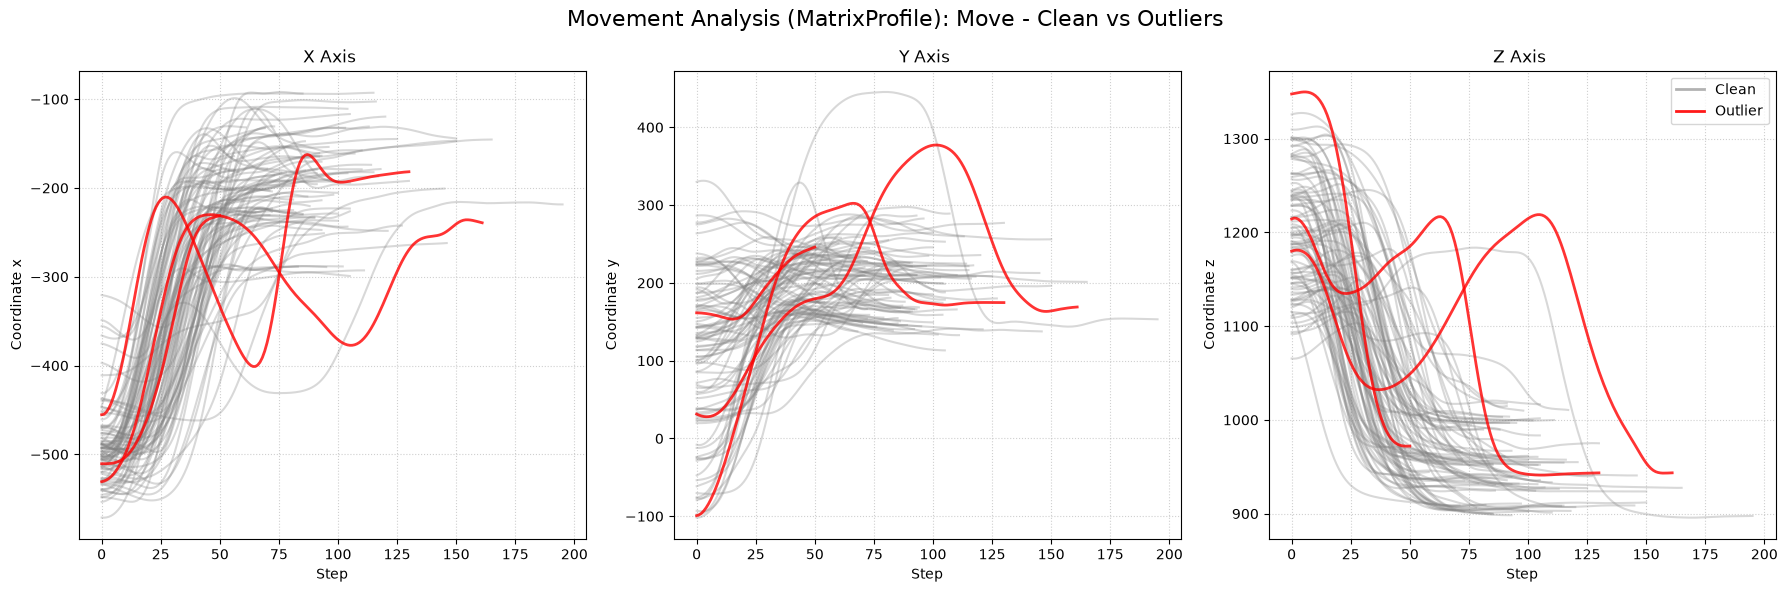

In [ ]:
# plot_movement_data(
#     clean_data=X_movement_clean,
#     outlier_data=X_movement_outliers,
#     target_movement=TARGET_MOVEMENT,
#     algorithm_name=ALGORITHM_NAME,
#     save_fig=Configs.SAVE_PLOTS,
#     save_path=Configs.DESKTOP_PATH,
#     model_representation=MODEL_REPRESENTATION
# )